# 05. Машинне навчання: Прогнозування стартів у [T, T+1h), перевірка на двох джерелах та Walk-Forward

Цей блокнот підсумовує результати моделювання на двох незалежних джерелах даних:
1. **Official (`official_data_uk.csv` -> `ml_features_hourly.parquet`):** `797,427` спокійних область-годин (`is_active_T == 0`, `0` дублікатів; у повному Test `2025-06-01 — 2026-09-07` — `197,083` спокійні область-години з `266,904` загальних).
2. **Volunteer (`volunteer_data_uk.csv` -> `volunteer_ml_features_hourly_*.parquet`):** друге незалежне джерело (`871,498` спокійних область-годин для варіанта `(а) naive_as_is` та `870,931` для каузального `(в) naive_fixed_D`; у повному Test `naive_fixed_D` — `256,485` спокійних область-годин, `naive_as_is` — `256,802`).

### Правило вибору моделі на Validation (сформульоване ретроспективно після первинного перегляду Test):
- **Методологічна прозорість:** правило відбору головної моделі серед сімейства кандидатів (`Baselines 1–3`, `LogReg A/B/C`, `LightGBM A/B/C`) за найвищим `PR-AUC` на `Validation` (`2024-05-01 — 2025-05-31`) було формалізоване ретроспективно після первинного ознайомлення з поведінкою моделей на `Test` (`selection rule formulated after initial Test inspection`), а не зареєстроване до початку експерименту.
- **Суворе відокремлення Early Stopping від Validation:** для `LightGBM` рання зупинка (`early_stopping(30)`) виконується виключно на внутрішньому хронологічному підвиділі хвоста `Train` (`Train_ES = останні 60 діб Train` із 2-годинним `embargo`; у Walk-Forward — останні `30` діб `Train_M` із 2-годинним `embargo`). Таким чином, вибірка `Validation` має нульовий перетин із ранньою зупинкою дерев і використовується виключно для калібрування порогу $p^* = \arg\max F_2$ (на єдиній сітці `np.linspace(0.01, 0.70, 175)`) та порівняння моделей за `Val PR-AUC`.
- За цим правилом на Validation обох джерел обрано **`LightGBM (Set C: Spatial + Adaptive)`** (`Val PR-AUC = 0.2967 [0.288, 0.306]` на Official та `0.3085 [0.301, 0.315]` на Volunteer `naive_as_is` / `0.3089` на `naive_fixed_D`).
- **Важливе застереження щодо Volunteer:** на тестовій вибірці Volunteer навіть після Walk-Forward перенавчання `LightGBM (Set C)` не є безумовно найкращим за всіма метриками — за об'єднаним `PR-AUC` він поступається `LogReg (Set C) [Static Initial Train]` (`0.3997` проти `0.4098`, $\Delta = -0.0101 \ [-0.0137, -0.0064]$) та `LogReg [WF Expanding]` (`0.4101`), переважаючи `LogReg Static` лише за $F_2$-мірою (`0.5972` проти `0.5924`, $\Delta = +0.0047 \ [+0.0027, +0.0068]$) та калібруванням `Brier Score` (`0.1098` проти `0.2645`).
- Експерименти `Set B` (як пост-хок лідер серед статичних моделей на Test Official), `Set C'` (19 ознак без найбільш нестаціонарних) та `Set D` (+відносні частки у Walk-Forward) явно позначені як **пост-хок (`post-hoc`)**.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

off_dir = Path("../reports/official")
vol_dir = Path("../reports/volunteer")
comp_dir = Path("../reports/comparison")

val_off = pd.read_csv(off_dir / "ml_validation_benchmark.csv")
test_off = pd.read_csv(off_dir / "ml_models_benchmark.csv")
pre_off = pd.read_csv(off_dir / "ml_test_pre_aug2025_benchmark.csv")
post_off = pd.read_csv(off_dir / "ml_test_post_aug2025_benchmark.csv")
rec_off = pd.read_csv(off_dir / "ml_recent_60d_benchmark.csv")

val_vol = pd.read_csv(vol_dir / "volunteer_ml_validation_benchmark.csv")
test_vol = pd.read_csv(vol_dir / "volunteer_ml_models_benchmark.csv")
rec_vol = pd.read_csv(vol_dir / "volunteer_ml_recent_60d_benchmark.csv")
sens_vol = pd.read_csv(vol_dir / "volunteer_naive_sensitivity.csv")

wf_off_full = pd.read_csv(off_dir / "walk_forward_overall_benchmark.csv")
wf_off_rec = pd.read_csv(off_dir / "walk_forward_recent_60d_benchmark.csv")
wf_off_m = pd.read_csv(off_dir / "walk_forward_monthly_metrics.csv")

wf_vol_full = pd.read_csv(vol_dir / "volunteer_walk_forward_overall_benchmark.csv")
wf_vol_rec = pd.read_csv(vol_dir / "volunteer_walk_forward_recent_60d_benchmark.csv")
wf_vol_m = pd.read_csv(vol_dir / "volunteer_walk_forward_monthly_metrics.csv")

## 1. Вибір моделі на Validation (2024-05 — 2025-05, Day-Block Bootstrap N=500)

In [2]:
cols_val = ["model", "threshold", "pr_auc", "pr_auc_ci_95", "f2_score", "f2_ci_95", "prec_at_adapt_recall", "selection_status"]
print("=== OFFICIAL: Validation (2024-05 — 2025-05) ===")
display(val_off[cols_val])
print("\n=== VOLUNTEER (naive_as_is): Validation (2024-05 — 2025-05) ===")
display(val_vol[cols_val])

=== OFFICIAL: Validation (2024-05 — 2025-05) ===


,model,threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall,selection_status
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.087718,"[0.079, 0.096]",NaN,candidate model (Val PR-AUC selection rule for...
1,Baseline 2: Historical Lookup Table,0.081379,0.194529,"[0.187, 0.202]",0.477021,"[0.469, 0.486]",0.187837,candidate model (Val PR-AUC selection rule for...
2,Baseline 3: Adaptive 14-day Rolling,0.085345,0.250806,"[0.242, 0.260]",0.488506,"[0.480, 0.497]",0.197934,candidate model (Val PR-AUC selection rule for...
3,LogReg (Set A: No Spatial),0.517586,0.266655,"[0.258, 0.277]",0.481581,"[0.473, 0.491]",0.191898,candidate model (Val PR-AUC selection rule for...
4,LogReg (Set B: With Spatial),0.561207,0.288188,"[0.280, 0.297]",0.504894,"[0.497, 0.513]",0.211920,candidate model (Val PR-AUC selection rule for...
5,LogReg (Set C: Spatial + Adaptive),0.565172,0.270128,"[0.262, 0.279]",0.522053,"[0.515, 0.529]",0.227355,candidate model (Val PR-AUC selection rule for...
6,LogReg (Set C': Adaptive + Lags),0.541379,0.288386,"[0.280, 0.297]",0.516896,"[0.510, 0.524]",0.222310,post-hoc sensitivity experiment (Set C')
7,LightGBM (Set A: No Spatial),0.097241,0.260093,"[0.251, 0.269]",0.483942,"[0.476, 0.492]",0.192128,candidate model (Val PR-AUC selection rule for...
8,LightGBM (Set B: With Spatial),0.113103,0.289321,"[0.281, 0.298]",0.522942,"[0.515, 0.531]",0.226878,candidate model (Val PR-AUC selection rule for...
9,LightGBM (Set C: Spatial + Adaptive),0.128966,0.296746,"[0.288, 0.306]",0.532719,"[0.525, 0.539]",0.237125,selected on Val by PR-AUC (rule formulated aft...



=== VOLUNTEER (naive_as_is): Validation (2024-05 — 2025-05) ===


,model,threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall,selection_status
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.099301,"[0.093, 0.107]",NaN,candidate model (Val PR-AUC selection rule for...
1,Baseline 2: Historical Lookup Table,0.077414,0.232123,"[0.225, 0.239]",0.496578,"[0.489, 0.504]",0.191065,candidate model (Val PR-AUC selection rule for...
2,Baseline 3: Adaptive 14-day Rolling,0.097241,0.266573,"[0.260, 0.273]",0.514699,"[0.508, 0.522]",0.209591,candidate model (Val PR-AUC selection rule for...
3,LogReg (Set A: No Spatial),0.497759,0.240072,"[0.233, 0.247]",0.503964,"[0.498, 0.510]",0.195242,candidate model (Val PR-AUC selection rule for...
4,LogReg (Set B: With Spatial),0.462069,0.275888,"[0.269, 0.282]",0.520123,"[0.514, 0.527]",0.213641,candidate model (Val PR-AUC selection rule for...
5,LogReg (Set C: Spatial + Adaptive),0.537414,0.293953,"[0.287, 0.300]",0.523648,"[0.517, 0.530]",0.215925,candidate model (Val PR-AUC selection rule for...
6,LogReg (Set C': Adaptive + Lags),0.477931,0.298219,"[0.291, 0.305]",0.524167,"[0.518, 0.531]",0.217285,post-hoc sensitivity experiment (Set C')
7,LightGBM (Set A: No Spatial),0.073448,0.247555,"[0.240, 0.255]",0.494794,"[0.488, 0.502]",0.191445,candidate model (Val PR-AUC selection rule for...
8,LightGBM (Set B: With Spatial),0.097241,0.281056,"[0.274, 0.287]",0.522750,"[0.516, 0.529]",0.214901,candidate model (Val PR-AUC selection rule for...
9,LightGBM (Set C: Spatial + Adaptive),0.121034,0.308508,"[0.301, 0.315]",0.530575,"[0.524, 0.537]",0.222895,selected on Val by PR-AUC (rule formulated aft...


## 2. Статичне навчання (2022–2024): Повний Test та Останні 60 днів на обох джерелах

In [3]:
cols_test = ["model", "frozen_threshold", "pr_auc", "pr_auc_ci_95", "f2_score", "f2_ci_95", "prec_at_adapt_recall", "selection_status"]
print("=== OFFICIAL: Повний Test (2025-06 — 2026-09) ===")
display(test_off[cols_test])
print("\n=== OFFICIAL: Останні 60 днів (2026-07-09 — 2026-09-07) ===")
display(rec_off[cols_test[:-1]])
print("\n=== VOLUNTEER (naive_as_is): Повний Test (2025-06 — 2026-10) ===")
display(test_vol[cols_test])
print("\n=== VOLUNTEER (naive_as_is): Останні 60 днів (2026-08-12 — 2026-10-11) ===")
display(rec_vol[cols_test[:-1]])

=== OFFICIAL: Повний Test (2025-06 — 2026-09) ===


,model,frozen_threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall,selection_status
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.103384,"[0.096, 0.111]",NaN,candidate model (Val PR-AUC selection rule for...
1,Baseline 2: Historical Lookup Table,0.081379,0.220406,"[0.212, 0.228]",0.504951,"[0.497, 0.513]",0.204572,candidate model (Val PR-AUC selection rule for...
2,Baseline 3: Adaptive 14-day Rolling,0.085345,0.303127,"[0.292, 0.315]",0.529298,"[0.519, 0.538]",0.227612,candidate model (Val PR-AUC selection rule for...
3,LogReg (Set A: No Spatial),0.517586,0.388104,"[0.377, 0.399]",0.532862,"[0.524, 0.541]",0.229582,candidate model (Val PR-AUC selection rule for...
4,LogReg (Set B: With Spatial),0.561207,0.390336,"[0.380, 0.400]",0.549922,"[0.541, 0.558]",0.247993,candidate model (Val PR-AUC selection rule for...
5,LogReg (Set C: Spatial + Adaptive),0.565172,0.317374,"[0.306, 0.329]",0.543077,"[0.535, 0.550]",0.250457,candidate model (Val PR-AUC selection rule for...
6,LogReg (Set C': Adaptive + Lags),0.541379,0.338564,"[0.327, 0.350]",0.552750,"[0.544, 0.561]",0.252219,post-hoc sensitivity experiment (Set C')
7,LightGBM (Set A: No Spatial),0.097241,0.339372,"[0.327, 0.351]",0.536027,"[0.527, 0.544]",0.228289,candidate model (Val PR-AUC selection rule for...
8,LightGBM (Set B: With Spatial),0.113103,0.361042,"[0.350, 0.372]",0.559399,"[0.550, 0.568]",0.262921,candidate model (Val PR-AUC selection rule for...
9,LightGBM (Set C: Spatial + Adaptive),0.128966,0.329192,"[0.319, 0.339]",0.555156,"[0.547, 0.562]",0.258682,selected on Val by PR-AUC (rule formulated aft...



=== OFFICIAL: Останні 60 днів (2026-07-09 — 2026-09-07) ===


,model,frozen_threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.162094,"[0.145, 0.181]",NaN
1,Baseline 2: Historical Lookup Table,0.081379,0.325750,"[0.295, 0.357]",0.590011,"[0.566, 0.614]",0.218278
2,Baseline 3: Adaptive 14-day Rolling,0.085345,0.368198,"[0.333, 0.406]",0.640524,"[0.617, 0.662]",0.293870
3,LogReg (Set A: No Spatial),0.517586,0.505830,"[0.480, 0.531]",0.653540,"[0.636, 0.674]",0.283568
4,LogReg (Set B: With Spatial),0.561207,0.478776,"[0.444, 0.510]",0.650106,"[0.626, 0.674]",0.299868
5,LogReg (Set C: Spatial + Adaptive),0.565172,0.388930,"[0.355, 0.424]",0.619630,"[0.592, 0.643]",0.303687
6,LogReg (Set C': Adaptive + Lags),0.541379,0.380255,"[0.343, 0.417]",0.649404,"[0.622, 0.675]",0.300930
7,LightGBM (Set A: No Spatial),0.097241,0.450782,"[0.424, 0.477]",0.654864,"[0.637, 0.674]",0.279199
8,LightGBM (Set B: With Spatial),0.113103,0.448441,"[0.415, 0.481]",0.644555,"[0.617, 0.670]",0.295628
9,LightGBM (Set C: Spatial + Adaptive),0.128966,0.382963,"[0.350, 0.416]",0.630120,"[0.603, 0.653]",0.293489



=== VOLUNTEER (naive_as_is): Повний Test (2025-06 — 2026-10) ===


,model,frozen_threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall,selection_status
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.190551,"[0.183, 0.198]",NaN,candidate model (Val PR-AUC selection rule for...
1,Baseline 2: Historical Lookup Table,0.077414,0.275596,"[0.270, 0.282]",0.541557,"[0.536, 0.547]",0.201494,candidate model (Val PR-AUC selection rule for...
2,Baseline 3: Adaptive 14-day Rolling,0.097241,0.392271,"[0.383, 0.401]",0.590030,"[0.584, 0.596]",0.253983,candidate model (Val PR-AUC selection rule for...
3,LogReg (Set A: No Spatial),0.497759,0.302099,"[0.296, 0.309]",0.558592,"[0.553, 0.564]",0.226917,candidate model (Val PR-AUC selection rule for...
4,LogReg (Set B: With Spatial),0.462069,0.326255,"[0.320, 0.333]",0.573172,"[0.568, 0.578]",0.235023,candidate model (Val PR-AUC selection rule for...
5,LogReg (Set C: Spatial + Adaptive),0.537414,0.409749,"[0.401, 0.418]",0.591890,"[0.585, 0.598]",0.254059,candidate model (Val PR-AUC selection rule for...
6,LogReg (Set C': Adaptive + Lags),0.477931,0.409712,"[0.401, 0.418]",0.593838,"[0.588, 0.600]",0.254937,post-hoc sensitivity experiment (Set C')
7,LightGBM (Set A: No Spatial),0.073448,0.299082,"[0.293, 0.306]",0.555635,"[0.550, 0.561]",0.220237,candidate model (Val PR-AUC selection rule for...
8,LightGBM (Set B: With Spatial),0.097241,0.313359,"[0.307, 0.320]",0.557312,"[0.552, 0.562]",0.225680,candidate model (Val PR-AUC selection rule for...
9,LightGBM (Set C: Spatial + Adaptive),0.121034,0.387655,"[0.380, 0.395]",0.594876,"[0.589, 0.601]",0.258458,selected on Val by PR-AUC (rule formulated aft...



=== VOLUNTEER (naive_as_is): Останні 60 днів (2026-08-12 — 2026-10-11) ===


,model,frozen_threshold,pr_auc,pr_auc_ci_95,f2_score,f2_ci_95,prec_at_adapt_recall
0,Baseline 1: True Naive Persistence,0.500000,NaN,-,0.269490,"[0.258, 0.283]",NaN
1,Baseline 2: Historical Lookup Table,0.077414,0.338465,"[0.325, 0.352]",0.545016,"[0.533, 0.557]",0.248098
2,Baseline 3: Adaptive 14-day Rolling,0.097241,0.480712,"[0.468, 0.496]",0.665570,"[0.656, 0.675]",0.304048
3,LogReg (Set A: No Spatial),0.497759,0.384294,"[0.370, 0.400]",0.565191,"[0.551, 0.580]",0.283944
4,LogReg (Set B: With Spatial),0.462069,0.388916,"[0.375, 0.403]",0.604740,"[0.592, 0.618]",0.280462
5,LogReg (Set C: Spatial + Adaptive),0.537414,0.500252,"[0.487, 0.516]",0.662370,"[0.654, 0.671]",0.303557
6,LogReg (Set C': Adaptive + Lags),0.477931,0.497930,"[0.486, 0.513]",0.665009,"[0.656, 0.674]",0.303543
7,LightGBM (Set A: No Spatial),0.073448,0.367097,"[0.352, 0.383]",0.569625,"[0.555, 0.584]",0.266433
8,LightGBM (Set B: With Spatial),0.097241,0.364693,"[0.351, 0.379]",0.590086,"[0.582, 0.599]",0.267336
9,LightGBM (Set C: Spatial + Adaptive),0.121034,0.454507,"[0.438, 0.473]",0.664652,"[0.655, 0.674]",0.306703


## 3. Аналіз чутливості до штучного кінця `naive` на волонтерських даних (`naive_as_is`, `drop_naive`, `naive_fixed_D`)

In [4]:
display(sens_vol)

,naive_variant,naive_description,model,calm_rows_total,calm_rows_test,test_positives,test_base_rate,test_mean_hours_since_last_alert,test_mean_burden_24h,val_threshold,...,test_precision,test_recall,test_f2,test_f2_ci_95,test_pr_auc,test_pr_auc_ci_95,delta_prauc_lgbC_minus_adapt,delta_prauc_ci_95,delta_f2_lgbC_minus_adapt,delta_f2_ci_95
0,naive_as_is,(а) naive як є (finished_at = started_at + 30 хв),Baseline 3: Adaptive 14-day Rolling,871498,256802,39329,0.15315,30.94,0.0921,0.0972,...,0.2540,0.8817,0.5900,"[0.584, 0.596]",0.3923,"[0.383, 0.401]",0.0000,-,0.0000,-
1,naive_as_is,(а) naive як є (finished_at = started_at + 30 хв),LightGBM (Set C: Spatial + Adaptive),871498,256802,39329,0.15315,30.94,0.0921,0.1210,...,0.2754,0.8378,0.5949,"[0.589, 0.601]",0.3877,"[0.380, 0.395]",-0.0043,"[-0.0080, -0.0001]",0.0048,"[+0.0021, +0.0076]"
2,drop_naive,(б) без наївних тривог (drop naive == True),Baseline 3: Adaptive 14-day Rolling,874368,258046,37190,0.14412,33.50,0.0880,0.0853,...,0.2369,0.8875,0.5729,"[0.566, 0.579]",0.3881,"[0.379, 0.397]",0.0000,-,0.0000,-
3,drop_naive,(б) без наївних тривог (drop naive == True),LightGBM (Set C: Spatial + Adaptive),874368,258046,37190,0.14412,33.50,0.0880,0.1012,...,0.2519,0.8686,0.5831,"[0.577, 0.589]",0.3825,"[0.375, 0.390]",-0.0053,"[-0.0095, -0.0009]",0.0102,"[+0.0077, +0.0130]"
4,naive_fixed_D,(в) каузальний naive_fixed_D (finished_at = st...,Baseline 3: Adaptive 14-day Rolling,870931,256485,39329,0.15334,30.96,0.0931,0.0972,...,0.2544,0.8817,0.5905,"[0.584, 0.596]",0.3925,"[0.384, 0.401]",0.0000,-,0.0000,-
5,naive_fixed_D,(в) каузальний naive_fixed_D (finished_at = st...,LightGBM (Set C: Spatial + Adaptive),870931,256485,39329,0.15334,30.96,0.0931,0.1171,...,0.2727,0.8484,0.5965,"[0.591, 0.602]",0.3865,"[0.379, 0.394]",-0.0057,"[-0.0095, -0.0016]",0.0059,"[+0.0034, +0.0085]"


## 4. Експеримент Walk-Forward (ковзне перенавчання 12m Train + 2m Val з 2h embargo для [T, T+1h))
- **Головна гіпотеза блоку Walk-Forward (`primary hypothesis of the WF block (specified after viewing static Test results)`):** `LightGBM (Set C) [WF Rolling 12m]` проти справедливого бейзлайну `Baseline 3: Adaptive 14-day (WF p*_M)` за парною різницею $\Delta\text{PR-AUC}$ (Day-Block Bootstrap $N=500$, `seed=42`).
- **Внутрішній спліт Early Stopping у кожному фолді $M$:** у кожному місяці $M$ для `LightGBM` останні `30` діб `Train_M` (із 2-годинним `embargo`) виділяються під `early_stopping(30)`, тому 2-місячне вікно `Val_M` не використовується під час побудови дерев і слугує виключно для калібрування порогу $p^*_M = \arg\max F_2$.
- **Статичний еталон (`Static Initial Train`):** на `Official` використовується заморожена модель `models/lightgbm_adaptive.joblib` ($p^*=0.1290$), а на `Volunteer (naive_fixed_D)` — заморожена модель `models/volunteer_lightgbm_adaptive_fixed_d.joblib` ($p^*=0.1171$), навчена безпосередньо на каузальній сітці `naive_fixed_D` (повна узгодженість із таблицею чутливості `volunteer_naive_sensitivity.csv`, де `PR-AUC = 0.3865`, `F2 = 0.5965`).
- **Прямий рядок «LogReg Static проти LGBM WF» та застереження щодо Volunteer:** у підсумкові таблиці нижче додано рядок `LogReg Static проти LGBM WF (Set C: LGBM_WF − LogReg_Static)`. На `Official` `LightGBM WF Rolling 12m` переважає `LogReg Static` як за `PR-AUC` ($+0.0986 \ [+0.0897, +0.1076]$ на повному Test; $+0.1135 \ [+0.0871, +0.1402]$ на останніх 60 днях), так і за $F_2$ ($+0.0307 \ [+0.0263, +0.0348]$). Проте на `Volunteer (naive_fixed_D)` `LightGBM WF Rolling 12m` поступається `LogReg Static` за `PR-AUC` ($-0.0101 \ [-0.0137, -0.0064]$ на повному Test та $-0.0089 \ [-0.0146, -0.0029]$ на останніх 60 днях), виграючи лише за $F_2$ ($+0.0047 \ [+0.0027, +0.0068]$ на повному Test та $+0.0051 \ [+0.0017, +0.0089]$ на останніх 60 днях) та `Brier Score` (`0.1098` проти `0.2645`). Тому називати `LightGBM` безумовно найкращою моделлю на Volunteer не можна.
- **Формулювання інтерпретації («узгоджується з»):** спостережуваний приріст Walk-Forward над статичним `LightGBM` **узгоджується з** гіпотезою про адаптацію до зміни режиму з червня 2025 року та зняттям насичення діапазону дерев наприкінці 2026 року (окремий інтервенційний тест для ізоляції причини не проводився).

In [5]:
cols_wf = ["model", "protocol_status", "pooled_pr_auc", "pr_auc_ci_95", "mean_monthly_pr_auc", "delta_prauc_vs_adapt_wf", "delta_prauc_vs_adapt_wf_ci_95", "prec_at_adapt_recall", "f2_score", "f2_ci_95"]
print("=== VOLUNTEER (naive_fixed_D): Walk-Forward — Повний Test (2025-06 — 2026-10) ===")
display(wf_vol_full[cols_wf])
print("\n=== VOLUNTEER (naive_fixed_D): Walk-Forward — Окремо Останні 60 днів (2026-08-12 — 2026-10-11) ===")
display(wf_vol_rec[cols_wf])
print("\n=== OFFICIAL: Walk-Forward — Повний Test (2025-06 — 2026-09) ===")
display(wf_off_full[cols_wf])
print("\n=== OFFICIAL: Walk-Forward — Окремо Останні 60 днів (2026-07-09 — 2026-09-07) ===")
display(wf_off_rec[cols_wf])

=== VOLUNTEER (naive_fixed_D): Walk-Forward — Повний Test (2025-06 — 2026-10) ===


,model,protocol_status,pooled_pr_auc,pr_auc_ci_95,mean_monthly_pr_auc,delta_prauc_vs_adapt_wf,delta_prauc_vs_adapt_wf_ci_95,prec_at_adapt_recall,f2_score,f2_ci_95
0,Reference: Predict-All (p* = 0.0),reference (base-rate F2 floor),NaN,-,NaN,NaN,-,0.153338,0.475216,"[0.467, 0.484]"
1,Baseline 3: Adaptive 14-day (Static Val p*),reference baseline (frozen Val p*),0.392527,"[0.384, 0.401]",0.365280,0.000000,"[+0.0000, +0.0000]",0.259355,0.590482,"[0.584, 0.596]"
2,Baseline 3: Adaptive 14-day (WF p*_M),PRIMARY FAIR BASELINE (WF p*_M),0.392527,"[0.384, 0.401]",0.365280,0.000000,"[+0.0000, +0.0000]",0.259355,0.590138,"[0.584, 0.596]"
3,LightGBM (Set C) [Static Initial Train],reference static model (selected by Val PR-AUC...,0.386490,"[0.379, 0.394]",0.375836,-0.005688,"[-0.0095, -0.0016]",0.265729,0.596477,"[0.591, 0.602]"
4,LogReg (Set C) [Static Initial Train],reference static model (trained on naive_fixed...,0.409818,"[0.401, 0.418]",0.394584,0.017414,"[+0.0150, +0.0200]",0.261645,0.592446,"[0.586, 0.598]"
5,LightGBM (Set C) [WF Rolling 12m],primary hypothesis of the WF block (specified ...,0.399701,"[0.391, 0.407]",0.388400,0.007362,"[+0.0027, +0.0121]",0.267321,0.597220,"[0.591, 0.603]"
6,LogReg (Set C) [WF Rolling 12m],exploratory (Set C under Val PR-AUC selection ...,0.405809,"[0.398, 0.414]",0.392078,0.013451,"[+0.0105, +0.0163]",0.263269,0.595090,"[0.589, 0.601]"
7,"LightGBM (Set D: +Rel Ratios) [WF Rolling 12m,...",post-hoc exploratory (Set D),0.400101,"[0.392, 0.408]",0.388568,0.007735,"[+0.0030, +0.0123]",0.268081,0.596462,"[0.591, 0.602]"
8,"LogReg (Set D: +Rel Ratios) [WF Rolling 12m, p...",post-hoc exploratory (Set D),0.406059,"[0.398, 0.415]",0.392219,0.013706,"[+0.0107, +0.0165]",0.263632,0.595072,"[0.589, 0.601]"
9,LightGBM (Set C) [WF Expanding],exploratory (expanding window),0.402876,"[0.395, 0.410]",0.391053,0.010562,"[+0.0065, +0.0148]",0.268820,0.598610,"[0.593, 0.604]"



=== VOLUNTEER (naive_fixed_D): Walk-Forward — Окремо Останні 60 днів (2026-08-12 — 2026-10-11) ===


,model,protocol_status,pooled_pr_auc,pr_auc_ci_95,mean_monthly_pr_auc,delta_prauc_vs_adapt_wf,delta_prauc_vs_adapt_wf_ci_95,prec_at_adapt_recall,f2_score,f2_ci_95
0,Reference: Predict-All (p* = 0.0),reference (base-rate F2 floor),NaN,-,NaN,NaN,-,0.222394,0.588476,"[0.575, 0.603]"
1,Baseline 3: Adaptive 14-day (Static Val p*),reference baseline (frozen Val p*),0.481041,"[0.469, 0.496]",0.479659,0.000000,"[+0.0000, +0.0000]",0.317450,0.666430,"[0.657, 0.676]"
2,Baseline 3: Adaptive 14-day (WF p*_M),PRIMARY FAIR BASELINE (WF p*_M),0.481041,"[0.469, 0.496]",0.479659,0.000000,"[+0.0000, +0.0000]",0.317450,0.665616,"[0.656, 0.675]"
3,LightGBM (Set C) [Static Initial Train],reference static model (selected by Val PR-AUC...,0.457905,"[0.443, 0.476]",0.461701,-0.022935,"[-0.0321, -0.0134]",0.317385,0.666710,"[0.657, 0.677]"
4,LogReg (Set C) [Static Initial Train],reference static model (trained on naive_fixed...,0.500252,"[0.487, 0.515]",0.503395,0.019423,"[+0.0133, +0.0257]",0.318214,0.663667,"[0.655, 0.673]"
5,LightGBM (Set C) [WF Rolling 12m],primary hypothesis of the WF block (specified ...,0.491302,"[0.478, 0.507]",0.495844,0.010493,"[+0.0016, +0.0199]",0.320812,0.668719,"[0.659, 0.678]"
6,LogReg (Set C) [WF Rolling 12m],exploratory (Set C under Val PR-AUC selection ...,0.498013,"[0.486, 0.513]",0.498519,0.017049,"[+0.0108, +0.0230]",0.322194,0.668840,"[0.660, 0.679]"
7,"LightGBM (Set D: +Rel Ratios) [WF Rolling 12m,...",post-hoc exploratory (Set D),0.491419,"[0.479, 0.507]",0.494567,0.010617,"[+0.0021, +0.0195]",0.319327,0.663692,"[0.654, 0.675]"
8,"LogReg (Set D: +Rel Ratios) [WF Rolling 12m, p...",post-hoc exploratory (Set D),0.498094,"[0.486, 0.513]",0.498523,0.017119,"[+0.0109, +0.0230]",0.322010,0.670375,"[0.662, 0.680]"
9,LightGBM (Set C) [WF Expanding],exploratory (expanding window),0.491528,"[0.479, 0.507]",0.493884,0.010716,"[+0.0024, +0.0193]",0.319969,0.668474,"[0.660, 0.678]"



=== OFFICIAL: Walk-Forward — Повний Test (2025-06 — 2026-09) ===


,model,protocol_status,pooled_pr_auc,pr_auc_ci_95,mean_monthly_pr_auc,delta_prauc_vs_adapt_wf,delta_prauc_vs_adapt_wf_ci_95,prec_at_adapt_recall,f2_score,f2_ci_95
0,Reference: Predict-All (p* = 0.0),reference (base-rate F2 floor),NaN,-,NaN,NaN,-,0.102749,0.364100,"[0.354, 0.373]"
1,Baseline 3: Adaptive 14-day (Static Val p*),reference baseline (frozen Val p*),0.303127,"[0.292, 0.315]",0.300925,0.000000,"[+0.0000, +0.0000]",0.231394,0.529298,"[0.519, 0.538]"
2,Baseline 3: Adaptive 14-day (WF p*_M),PRIMARY FAIR BASELINE (WF p*_M),0.303127,"[0.292, 0.315]",0.300925,0.000000,"[+0.0000, +0.0000]",0.231394,0.527491,"[0.518, 0.536]"
3,LightGBM (Set C) [Static Initial Train],reference static model (selected by Val PR-AUC...,0.329192,"[0.319, 0.339]",0.330140,0.025964,"[+0.0182, +0.0333]",0.261375,0.555156,"[0.547, 0.562]"
4,LogReg (Set C) [Static Initial Train],reference static model (frozen logreg_adaptive...,0.317374,"[0.306, 0.329]",0.318359,0.014108,"[+0.0090, +0.0200]",0.251749,0.543077,"[0.535, 0.550]"
5,LightGBM (Set C) [WF Rolling 12m],primary hypothesis of the WF block (specified ...,0.415988,"[0.405, 0.426]",0.419350,0.112725,"[+0.1035, +0.1216]",0.276021,0.573908,"[0.566, 0.582]"
6,LogReg (Set C) [WF Rolling 12m],exploratory (Set C under Val PR-AUC selection ...,0.396371,"[0.386, 0.407]",0.396368,0.093175,"[+0.0849, +0.1017]",0.266050,0.563605,"[0.555, 0.572]"
7,"LightGBM (Set D: +Rel Ratios) [WF Rolling 12m,...",post-hoc exploratory (Set D),0.415218,"[0.405, 0.425]",0.418799,0.111860,"[+0.1025, +0.1212]",0.276059,0.571555,"[0.563, 0.580]"
8,"LogReg (Set D: +Rel Ratios) [WF Rolling 12m, p...",post-hoc exploratory (Set D),0.396397,"[0.386, 0.407]",0.396202,0.093210,"[+0.0848, +0.1018]",0.264853,0.563117,"[0.554, 0.572]"
9,LightGBM (Set C) [WF Expanding],exploratory (expanding window),0.419133,"[0.408, 0.429]",0.421157,0.115854,"[+0.1071, +0.1246]",0.274771,0.570015,"[0.561, 0.578]"



=== OFFICIAL: Walk-Forward — Окремо Останні 60 днів (2026-07-09 — 2026-09-07) ===


,model,protocol_status,pooled_pr_auc,pr_auc_ci_95,mean_monthly_pr_auc,delta_prauc_vs_adapt_wf,delta_prauc_vs_adapt_wf_ci_95,prec_at_adapt_recall,f2_score,f2_ci_95
0,Reference: Predict-All (p* = 0.0),reference (base-rate F2 floor),NaN,-,NaN,NaN,-,0.126533,0.420060,"[0.395, 0.442]"
1,Baseline 3: Adaptive 14-day (Static Val p*),reference baseline (frozen Val p*),0.368198,"[0.333, 0.406]",0.343094,0.000000,"[+0.0000, +0.0000]",0.326598,0.640524,"[0.617, 0.662]"
2,Baseline 3: Adaptive 14-day (WF p*_M),PRIMARY FAIR BASELINE (WF p*_M),0.368198,"[0.333, 0.406]",0.343094,0.000000,"[+0.0000, +0.0000]",0.326598,0.639857,"[0.615, 0.665]"
3,LightGBM (Set C) [Static Initial Train],reference static model (selected by Val PR-AUC...,0.382963,"[0.350, 0.416]",0.364325,0.014828,"[-0.0032, +0.0317]",0.320755,0.630120,"[0.603, 0.653]"
4,LogReg (Set C) [Static Initial Train],reference static model (frozen logreg_adaptive...,0.388930,"[0.355, 0.424]",0.381370,0.020531,"[+0.0052, +0.0349]",0.334542,0.619630,"[0.592, 0.643]"
5,LightGBM (Set C) [WF Rolling 12m],primary hypothesis of the WF block (specified ...,0.502426,"[0.475, 0.531]",0.521874,0.133858,"[+0.1006, +0.1655]",0.337513,0.657701,"[0.633, 0.681]"
6,LogReg (Set C) [WF Rolling 12m],exploratory (Set C under Val PR-AUC selection ...,0.471882,"[0.446, 0.499]",0.483518,0.103865,"[+0.0798, +0.1293]",0.346427,0.664720,"[0.641, 0.688]"
7,"LightGBM (Set D: +Rel Ratios) [WF Rolling 12m,...",post-hoc exploratory (Set D),0.501298,"[0.472, 0.530]",0.520130,0.133167,"[+0.1018, +0.1638]",0.337425,0.657572,"[0.634, 0.681]"
8,"LogReg (Set D: +Rel Ratios) [WF Rolling 12m, p...",post-hoc exploratory (Set D),0.471817,"[0.447, 0.499]",0.481831,0.103751,"[+0.0797, +0.1291]",0.346427,0.663768,"[0.640, 0.687]"
9,LightGBM (Set C) [WF Expanding],exploratory (expanding window),0.515143,"[0.490, 0.542]",0.524065,0.146389,"[+0.1213, +0.1724]",0.340448,0.657494,"[0.635, 0.680]"


## 5. Помісячна таблиця PR-AUC та діагностики виходу за межі Train (Volunteer: 13 із 17 перемог над Static, 14 із 17 над Adaptive; Official: 16 із 16 перемог)

In [6]:
cols_m = ["month", "actual_base_rate", "share_gt_static_train_max", "share_gt_roll12m_train_max", "prauc_adapt", "prauc_static_lgb_c", "prauc_wf_roll12m_lgb_c", "prauc_wf_exp_lgb_c", "prauc_wf_roll12m_lgb_d", "prauc_wf_roll12m_lr_c"]
print("=== VOLUNTEER (naive_fixed_D): Помісячні метрики (17 місяців) ===")
display(wf_vol_m[cols_m])
print("\n=== OFFICIAL: Помісячні метрики (16 місяців) ===")
display(wf_off_m[cols_m])

=== VOLUNTEER (naive_fixed_D): Помісячні метрики (17 місяців) ===


,month,actual_base_rate,share_gt_static_train_max,share_gt_roll12m_train_max,prauc_adapt,prauc_static_lgb_c,prauc_wf_roll12m_lgb_c,prauc_wf_exp_lgb_c,prauc_wf_roll12m_lgb_d,prauc_wf_roll12m_lr_c
0,2025-06,0.10526,0.0000,0.0000,0.2597,0.3037,0.3306,0.3228,0.3309,0.3064
1,2025-07,0.12312,0.0000,0.0000,0.2704,0.3177,0.3313,0.3340,0.3288,0.3087
2,2025-08,0.11399,0.0000,0.0000,0.2898,0.3150,0.3324,0.3317,0.3299,0.3226
3,2025-09,0.12421,0.0000,0.0000,0.2800,0.3211,0.3332,0.3300,0.3295,0.3293
4,2025-10,0.12267,0.0000,0.0000,0.2841,0.3175,0.3356,0.3266,0.3359,0.3172
5,2025-11,0.14063,0.0000,0.0000,0.3072,0.3192,0.3209,0.3308,0.3224,0.3238
6,2025-12,0.12991,0.0000,0.0000,0.3112,0.3316,0.3368,0.3457,0.3448,0.3312
7,2026-01,0.14503,0.0177,0.0364,0.3375,0.3561,0.3326,0.3576,0.3323,0.3461
8,2026-02,0.15047,0.0219,0.0438,0.3407,0.3649,0.3587,0.3726,0.3632,0.3751
9,2026-03,0.17053,0.0795,0.0856,0.4267,0.4236,0.4169,0.4263,0.4187,0.4521



=== OFFICIAL: Помісячні метрики (16 місяців) ===


,month,actual_base_rate,share_gt_static_train_max,share_gt_roll12m_train_max,prauc_adapt,prauc_static_lgb_c,prauc_wf_roll12m_lgb_c,prauc_wf_exp_lgb_c,prauc_wf_roll12m_lgb_d,prauc_wf_roll12m_lr_c
0,2025-06,0.08903,0.0000,0.0000,0.2752,0.2937,0.3770,0.3651,0.3726,0.3031
1,2025-07,0.10329,0.0000,0.0000,0.2697,0.2923,0.3407,0.3339,0.3383,0.3042
2,2025-08,0.09214,0.0000,0.0008,0.3035,0.3480,0.3697,0.3760,0.3731,0.3470
3,2025-09,0.08875,0.0000,0.0000,0.2877,0.3413,0.4190,0.4270,0.4169,0.3748
4,2025-10,0.08416,0.0000,0.0000,0.2685,0.3160,0.3242,0.3412,0.3212,0.3478
5,2025-11,0.09973,0.0000,0.0000,0.2658,0.2958,0.3442,0.3420,0.3376,0.3414
6,2025-12,0.09042,0.0000,0.0000,0.2823,0.3378,0.3612,0.3679,0.3663,0.3498
7,2026-01,0.10057,0.0000,0.0000,0.2592,0.2988,0.3671,0.3722,0.3727,0.3598
8,2026-02,0.10904,0.0000,0.0000,0.2772,0.3103,0.3983,0.4116,0.4003,0.3740
9,2026-03,0.11334,0.0000,0.0000,0.3804,0.4045,0.4858,0.4911,0.4814,0.4680


### 5.3. Регіональний описовий розріз Walk-Forward проти Static та Adaptive (24 області, Exploratory)

- **Статус блоку:** `exploratory` (24 області × 2 джерела = множинні порівняння; жодних тверджень про статистичну значущість окремих областей не робиться).
- **Групування:** виключно за Train-only кластерами (`активність 2022–04.2024`: `high_activity`, `medium_activity`, `low_activity`).
- **Малі вибірки:** усі 24 області залишені без відсікання; області з `n_positives < 150` або `n_calm_hours < 1500` на повному Test позначені прапорцем `low_sample_flag = True`.
- **Методологічне застереження:** абсолютний `PR-AUC` у межах області механічно залежить від її базової частоти (`base_rate`), тому між областями коректно порівнювати лише парні внутрішньообласні різниці `ΔPR-AUC (WF − Static)` та `ΔPR-AUC (WF − Adaptive)` з Day-Block Bootstrap (`N = 500`, `seed = 42`).

In [7]:
reg_clusters = pd.read_csv(comp_dir / "official_vs_volunteer_walk_forward_regional_clusters.csv")
reg_vol = pd.read_csv(vol_dir / "volunteer_walk_forward_regional_breakdown.csv")
reg_off = pd.read_csv(off_dir / "walk_forward_regional_breakdown.csv")

print("=== ЗВЕДЕННЯ ЗА TRAIN-ONLY КЛАСТЕРАМИ (активність 2022–04.2024) ===")
display(reg_clusters)

cols_reg = [
    "oblast", "train_cluster_label", "n_calm_hours", "n_positives", "base_rate",
    "low_sample_flag", "prauc_adapt", "prauc_static_lgb_c", "prauc_wf_roll12m_lgb_c",
    "delta_prauc_wf_minus_static", "delta_prauc_wf_minus_static_ci_95",
    "delta_prauc_wf_minus_adapt", "delta_prauc_wf_minus_adapt_ci_95",
]
print("\n=== VOLUNTEER (naive_fixed_D): Регіональний розріз (24 області, Full Test) ===")
display(reg_vol[cols_reg])
print("\n=== OFFICIAL: Регіональний розріз (24 області, Full Test) ===")
display(reg_off[cols_reg])

=== ЗВЕДЕННЯ ЗА TRAIN-ONLY КЛАСТЕРАМИ (активність 2022–04.2024) ===


,dataset,train_cluster_label,n_oblasts,n_low_sample_oblasts,mean_base_rate,median_prauc_adapt,median_prauc_static_lgb_c,median_prauc_wf_roll12m_lgb_c,mean_delta_wf_minus_static,median_delta_wf_minus_static,mean_delta_wf_minus_adapt,median_delta_wf_minus_adapt,n_wf_gt_static,n_wf_gt_adapt
0,Official,high_activity (активність 2022–04.2024),12,2,0.2908,0.3100,0.3471,0.3393,0.0443,0.0186,0.0877,0.0504,11,12
1,Official,medium_activity (активність 2022–04.2024),5,0,0.0611,0.0720,0.1567,0.1812,0.0332,0.0349,0.1148,0.1028,5,5
2,Official,low_activity (активність 2022–04.2024),7,1,0.0174,0.0189,0.1153,0.1281,0.0187,0.0187,0.1182,0.1091,7,7
3,Volunteer (naive_fixed_D),high_activity (активність 2022–04.2024),10,0,0.2887,0.3156,0.3300,0.3448,0.0189,0.0155,0.0299,0.0349,7,10
4,Volunteer (naive_fixed_D),medium_activity (активність 2022–04.2024),7,0,0.0989,0.1329,0.1847,0.1872,0.0074,0.0033,0.0463,0.0435,5,7
5,Volunteer (naive_fixed_D),low_activity (активність 2022–04.2024),7,1,0.0440,0.0224,0.0714,0.0768,0.0029,0.0054,0.0253,0.0192,6,7



=== VOLUNTEER (naive_fixed_D): Регіональний розріз (24 області, Full Test) ===


,oblast,train_cluster_label,n_calm_hours,n_positives,base_rate,low_sample_flag,prauc_adapt,prauc_static_lgb_c,prauc_wf_roll12m_lgb_c,delta_prauc_wf_minus_static,delta_prauc_wf_minus_static_ci_95,delta_prauc_wf_minus_adapt,delta_prauc_wf_minus_adapt_ci_95
0,Харківська область,high_activity (активність 2022–04.2024),9461,4461,0.47151,False,0.5636,0.5516,0.5975,0.0459,"[+0.0329, +0.0599]",0.0339,"[+0.0200, +0.0469]"
1,Дніпропетровська область,high_activity (активність 2022–04.2024),9917,4439,0.44762,False,0.5469,0.5403,0.5895,0.0492,"[+0.0372, +0.0618]",0.0426,"[+0.0316, +0.0547]"
2,Сумська область,high_activity (активність 2022–04.2024),9496,3419,0.36005,False,0.4041,0.4137,0.4430,0.0293,"[+0.0184, +0.0412]",0.0389,"[+0.0250, +0.0551]"
3,Чернігівська область,high_activity (активність 2022–04.2024),9608,2723,0.28341,False,0.3351,0.3547,0.3516,-0.0031,"[-0.0140, +0.0083]",0.0165,"[+0.0030, +0.0290]"
4,Запорізька область,high_activity (активність 2022–04.2024),9522,2567,0.26959,False,0.2962,0.3052,0.3379,0.0327,"[+0.0220, +0.0435]",0.0417,"[+0.0293, +0.0583]"
5,Миколаївська область,high_activity (активність 2022–04.2024),10348,2622,0.25338,False,0.3821,0.4031,0.4010,-0.0021,"[-0.0135, +0.0119]",0.0188,"[+0.0099, +0.0297]"
6,Полтавська область,high_activity (активність 2022–04.2024),10253,2320,0.22628,False,0.2698,0.2824,0.2840,0.0016,"[-0.0065, +0.0084]",0.0141,"[+0.0026, +0.0261]"
7,Херсонська область,high_activity (активність 2022–04.2024),10399,2268,0.21810,False,0.2463,0.2935,0.2895,-0.0040,"[-0.0135, +0.0057]",0.0432,"[+0.0298, +0.0568]"
8,Донецька область,high_activity (активність 2022–04.2024),9010,1808,0.20067,False,0.2273,0.2241,0.2634,0.0393,"[+0.0303, +0.0480]",0.0360,"[+0.0246, +0.0494]"
9,Кіровоградська область,high_activity (активність 2022–04.2024),10656,1667,0.15644,False,0.2233,0.2361,0.2365,0.0004,"[-0.0071, +0.0090]",0.0132,"[+0.0028, +0.0260]"



=== OFFICIAL: Регіональний розріз (24 області, Full Test) ===


,oblast,train_cluster_label,n_calm_hours,n_positives,base_rate,low_sample_flag,prauc_adapt,prauc_static_lgb_c,prauc_wf_roll12m_lgb_c,delta_prauc_wf_minus_static,delta_prauc_wf_minus_static_ci_95,delta_prauc_wf_minus_adapt,delta_prauc_wf_minus_adapt_ci_95
0,Донецька область,high_activity (активність 2022–04.2024),1037,623,0.60077,True,0.5606,0.6021,0.6608,0.0587,"[+0.0204, +0.0943]",0.1002,"[+0.0642, +0.1334]"
1,Харківська область,high_activity (активність 2022–04.2024),2957,1549,0.52384,False,0.5011,0.5674,0.6962,0.1288,"[+0.1021, +0.1554]",0.1951,"[+0.1642, +0.2302]"
2,Сумська область,high_activity (активність 2022–04.2024),2714,1419,0.52284,False,0.4856,0.5758,0.6950,0.1192,"[+0.0917, +0.1454]",0.2094,"[+0.1734, +0.2456]"
3,Запорізька область,high_activity (активність 2022–04.2024),4378,1664,0.38008,False,0.3621,0.4303,0.5824,0.1521,"[+0.1252, +0.1751]",0.2203,"[+0.1900, +0.2472]"
4,Чернігівська область,high_activity (активність 2022–04.2024),4416,1408,0.31884,False,0.4124,0.4688,0.4969,0.0281,"[+0.0001, +0.0543]",0.0845,"[+0.0486, +0.1171]"
5,Полтавська область,high_activity (активність 2022–04.2024),7663,1769,0.23085,False,0.2908,0.3089,0.3279,0.0190,"[+0.0051, +0.0343]",0.0372,"[+0.0190, +0.0574]"
6,Миколаївська область,high_activity (активність 2022–04.2024),8919,1733,0.19430,False,0.3203,0.3526,0.3368,-0.0158,"[-0.0352, +0.0018]",0.0165,"[-0.0068, +0.0390]"
7,Херсонська область,high_activity (активність 2022–04.2024),8498,1629,0.19169,False,0.2574,0.2940,0.3063,0.0122,"[-0.0040, +0.0280]",0.0489,"[+0.0288, +0.0689]"
8,Одеська область,high_activity (активність 2022–04.2024),9265,1642,0.17723,False,0.2997,0.3416,0.3419,0.0003,"[-0.0159, +0.0173]",0.0422,"[+0.0202, +0.0617]"
9,Кіровоградська область,high_activity (активність 2022–04.2024),9313,1319,0.14163,False,0.1946,0.2208,0.2291,0.0084,"[-0.0047, +0.0224]",0.0346,"[+0.0192, +0.0539]"


## 6. Ключові візуалізації (Official, Volunteer та Walk-Forward)

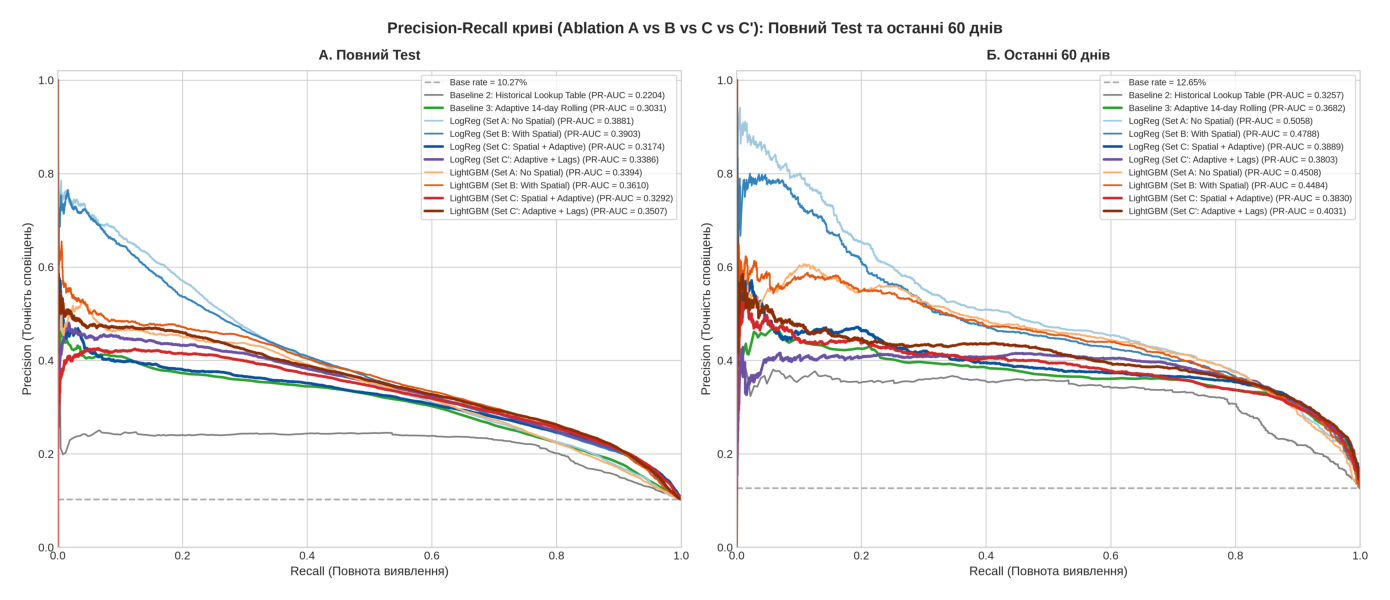

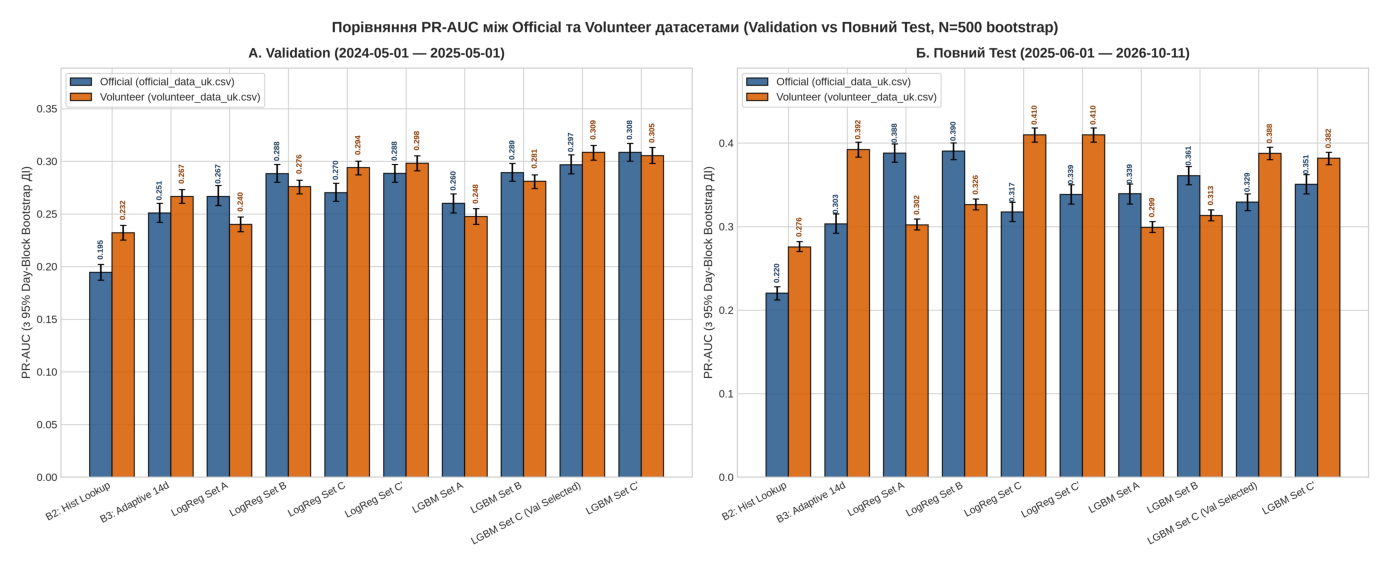

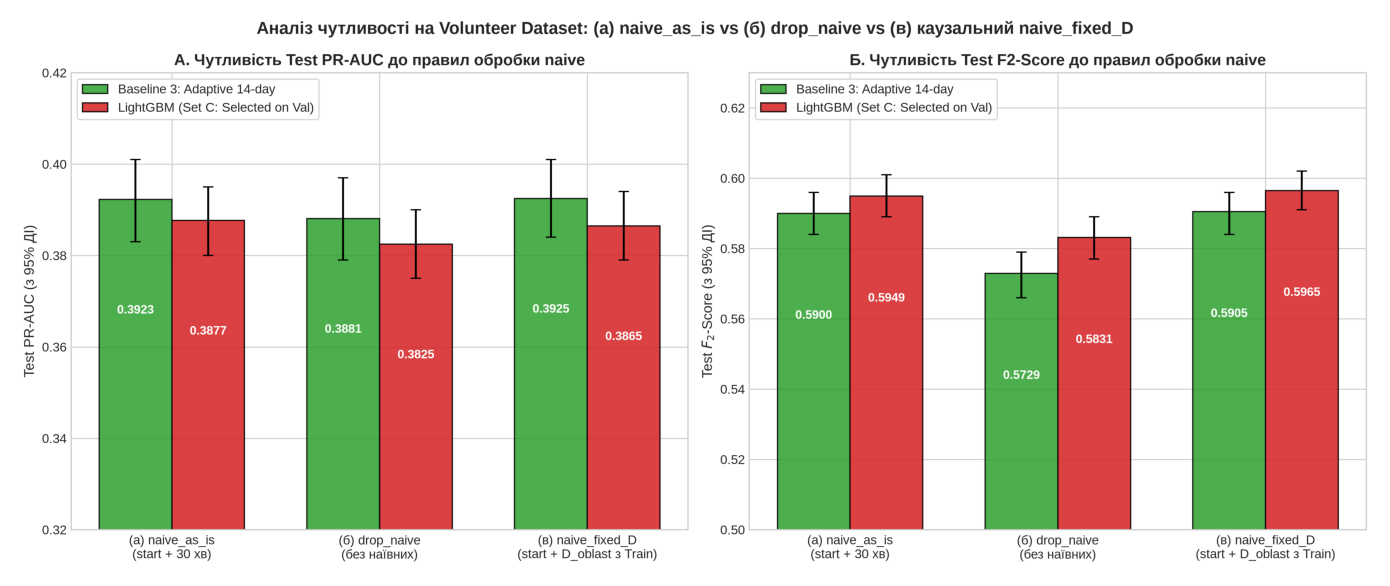

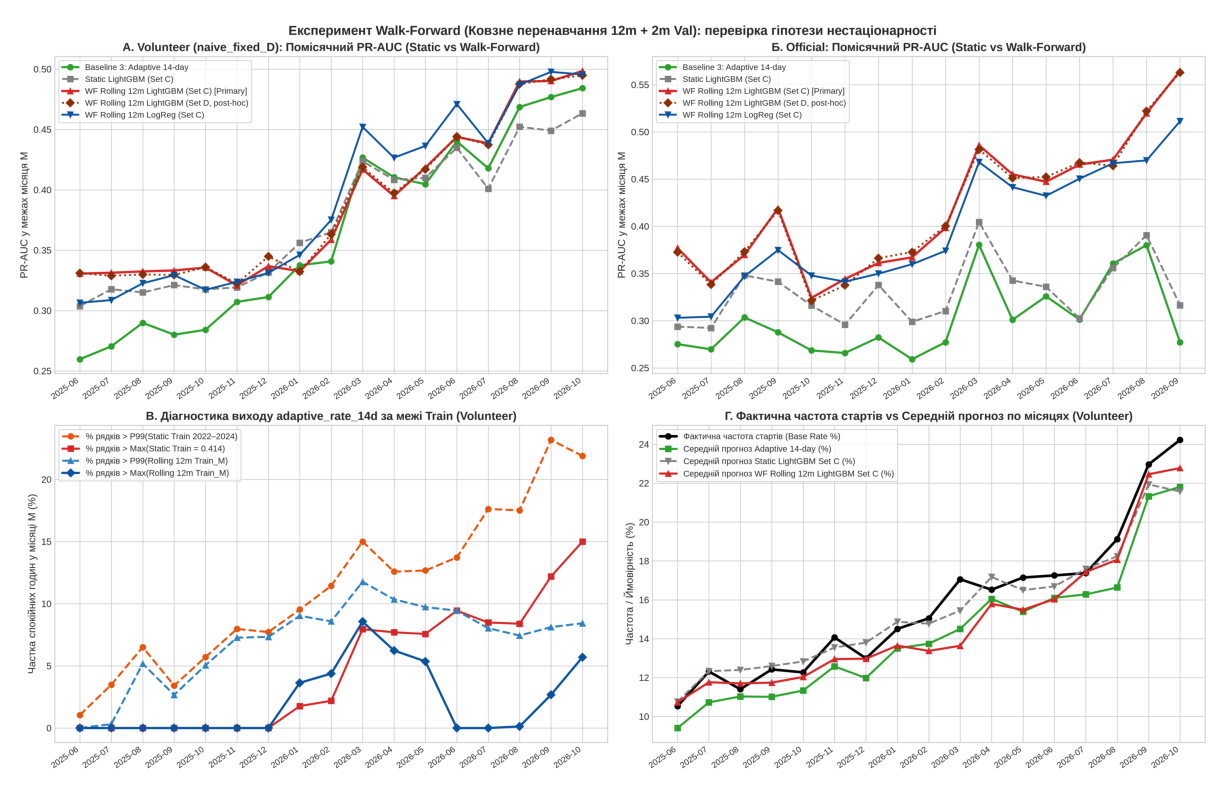

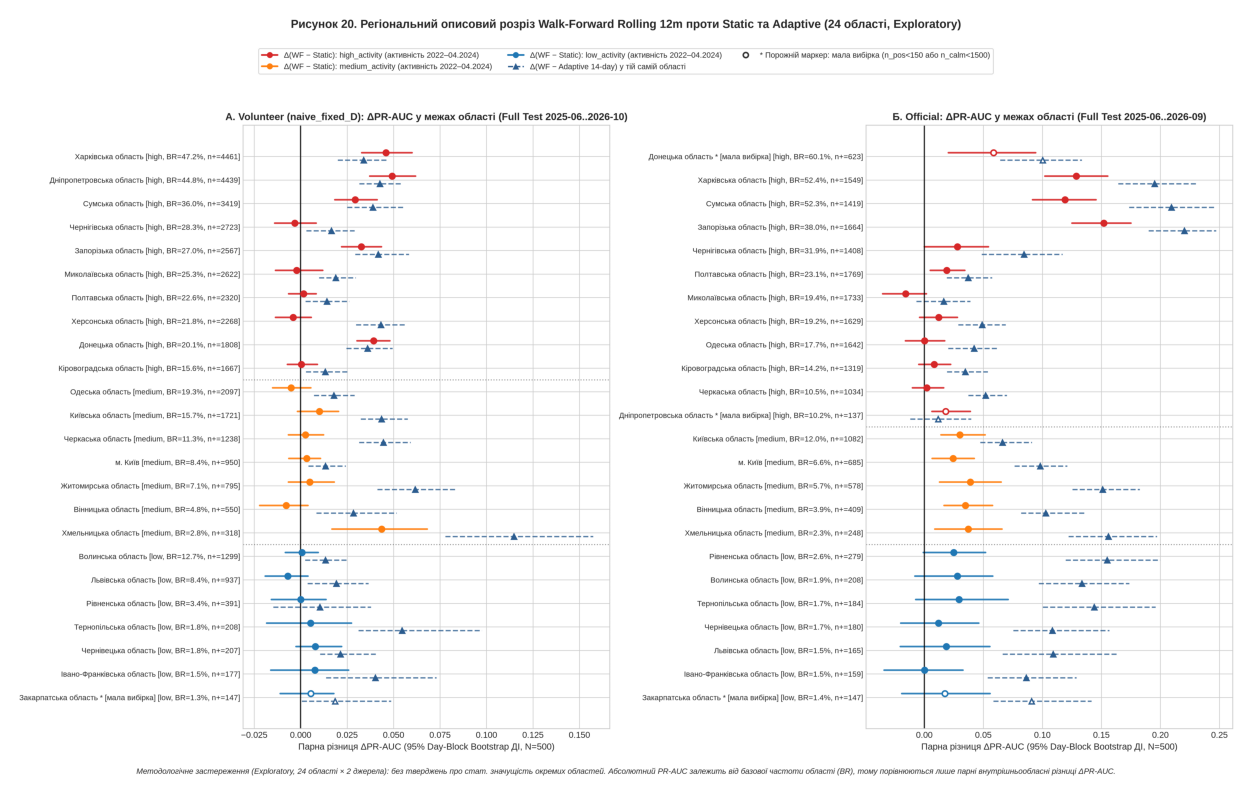

In [8]:
for fig_path in [
    off_dir / "figures" / "10_test_pr_curves_comparison.png",
    comp_dir / "figures" / "14_comparison_pr_auc_official_vs_volunteer.png",
    comp_dir / "figures" / "18_volunteer_naive_sensitivity_comparison.png",
    comp_dir / "figures" / "19_walk_forward_vs_static_comparison.png",
    comp_dir / "figures" / "20_walk_forward_regional_breakdown.png",
]:
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(mpimg.imread(fig_path))
    ax.axis("off")
    plt.tight_layout()
    plt.show()